# Práctica — Selección de variables con redes neuronales
## Consigna 2: clasificación no temporal de diagnósticos

**Alumno:** Juan Pablo Pillack  
**Materia:** Inteligencia Artificial · Semana 6, clase 6 · Ingeniería y selección de características
**Dataset:** *Breast Cancer Wisconsin (Diagnostic)* (UCI ML Repository, id 17, licencia CC BY 4.0)

> Uso exclusivamente educativo; los resultados **no** constituyen una herramienta clínica.

**Objetivo.** Explorar las 30 características, identificar variables relevantes o redundantes y comparar
una RNA entrenada con las 30 variables contra **la misma arquitectura** entrenada con un subconjunto
seleccionado, para clasificar el diagnóstico (maligno = 1, benigno = 0).

### Reglas que respeta todo el notebook

| Regla de la consigna | Cómo se cumple acá |
|---|---|
| Excluir identificadores | `ID` se descarta (y se verifica que no quede ninguna columna identificadora). |
| Partición estratificada | Se usa la del código inicial: prueba 20 % estratificada; validación 25 % del resto, también estratificada (341 / 114 / 114). |
| Escalado y selección solo con entrenamiento | El `StandardScaler` vive dentro del `Pipeline` (se ajusta con train); en L1 también se reajusta dentro de cada fold al elegir la penalización. Todos los rankings (ANOVA, información mutua, L1, RFE) y la redundancia se calculan **solo con `X_train`**. En la validación cruzada, la selección se **rehace dentro de cada fold**. |
| Misma arquitectura y particiones | Una única función `crear_rna()`; todos los experimentos solo cambian las columnas. |
| Prueba reservada | `X_test` se usa en una sola celda, al final, con la configuración congelada. |
| Atención a malignos no detectados | Se reportan recall de la clase maligna y **falsos negativos** en cada comparación. |

## 1. Preparación del entorno

In [1]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
SEMILLA = 42

## 2. Descarga y verificación (actividad 1)

In [3]:
cancer = fetch_ucirepo(id=17)
X = cancer.data.features.copy()
X = X.drop(columns=["ID"], errors="ignore")
y = cancer.data.targets.squeeze().map({"B": 0, "M": 1})

print(X.shape)
print(y.value_counts().rename({0: "benigno (0)", 1: "maligno (1)"}))
print(f"Proporción de malignos: {y.mean():.3f}")
print("Columnas tipo identificador:", [c for c in X.columns if "id" in c.lower()] or "ninguna")
print("Identificador provisto aparte por ucimlrepo:", list(cancer.data.ids.columns), "(no se usa)")
print("Faltantes:", int(X.isna().sum().sum()))
display(X.head())

(569, 30)
Diagnosis
benigno (0)    357
maligno (1)    212
Name: count, dtype: int64
Proporción de malignos: 0.373
Columnas tipo identificador: ninguna
Identificador provisto aparte por ucimlrepo: ['ID'] (no se usa)
Faltantes: 0


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.118,0.278,0.300,0.147,0.242,0.079,...,25.38,17.33,184.60,2019.0,0.162,0.666,0.712,0.265,0.460,0.119
1,20.57,17.77,132.90,1326.0,0.085,0.079,0.087,0.070,0.181,0.057,...,24.99,23.41,158.80,1956.0,0.124,0.187,0.242,0.186,0.275,0.089
2,19.69,21.25,130.00,1203.0,0.110,0.160,0.197,0.128,0.207,0.060,...,23.57,25.53,152.50,1709.0,0.144,0.424,0.450,0.243,0.361,0.088
3,11.42,20.38,77.58,386.1,0.142,0.284,0.241,0.105,0.260,0.097,...,14.91,26.50,98.87,567.7,0.210,0.866,0.687,0.258,0.664,0.173
4,20.29,14.34,135.10,1297.0,0.100,0.133,0.198,0.104,0.181,0.059,...,22.54,16.67,152.20,1575.0,0.137,0.205,0.400,0.163,0.236,0.077


Las 30 variables son **10 medidas** del núcleo celular (radio, textura, perímetro, área, suavidad,
compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal), cada una resumida de **3 formas**
sobre los núcleos de la imagen:

| Sufijo | Resumen |
|---|---|
| `1` | media |
| `2` | error estándar (*se*) |
| `3` | "peor" valor (media de los 3 núcleos más grandes) |

### Escalas

In [4]:
escalas = X.describe().T[["mean", "std", "min", "max"]]
display(escalas.sort_values("max", ascending=False))
print(f"Cociente entre el máximo más grande y el más chico: {escalas['max'].max() / escalas['max'].min():,.0f}x")

,mean,std,min,max
area3,880.583,569.357,1.852e+02,4254.000
area1,654.889,351.914,1.435e+02,2501.000
area2,40.337,45.491,6.802e+00,542.200
perimeter3,107.261,33.603,5.041e+01,251.200
perimeter1,91.969,24.299,4.379e+01,188.500
texture3,25.677,6.146,1.202e+01,49.540
texture1,19.290,4.301,9.710e+00,39.280
radius3,16.269,4.833,7.930e+00,36.040
radius1,14.127,3.524,6.981e+00,28.110
perimeter2,2.866,2.022,7.570e-01,21.980


Cociente entre el máximo más grande y el más chico: 142,560x


Las escalas difieren en **más de 4 órdenes de magnitud** (`area3` llega a miles; `fractal_dimension2`
ronda 0,003). Sin estandarizar, la red quedaría dominada por las áreas: por eso el `StandardScaler` es
obligatorio, y se ajusta solo con entrenamiento (dentro del `Pipeline`).

## 3. Particiones estratificadas (actividad 5)

Exactamente las del código inicial. Se hacen **antes** de cualquier análisis de relevancia.

In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEMILLA)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEMILLA)

display(pd.DataFrame({
    "filas": [len(X_train), len(X_val), len(X_test)],
    "malignos": [y_train.sum(), y_val.sum(), y_test.sum()],
    "prop. malignos": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["train", "validación", "prueba"]))

,filas,malignos,prop. malignos
train,341,127,0.372
validación,114,43,0.377
prueba,114,42,0.368


## 4. Correlaciones y redundancia (solo entrenamiento) — actividades 1 y 2

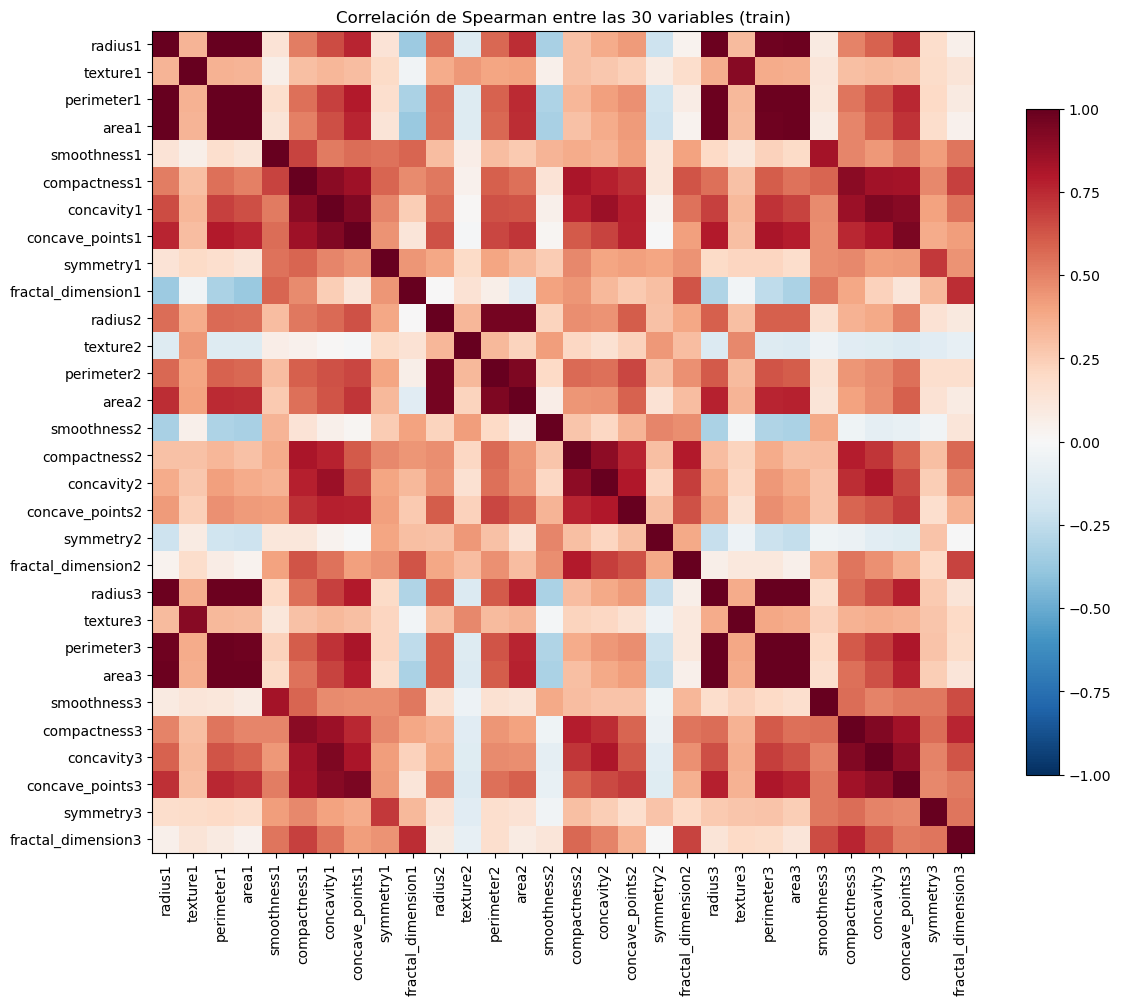

In [6]:
corr_train = X_train.corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr_train, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(30)); ax.set_xticklabels(corr_train.columns, rotation=90)
ax.set_yticks(range(30)); ax.set_yticklabels(corr_train.columns)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlación de Spearman entre las 30 variables (train)")
plt.tight_layout(); plt.show()

### 4.1 Radio, perímetro y área

Geométricamente, perímetro ≈ 2πr y área ≈ πr²: deberían ser casi la misma información.

,radius1,perimeter1,area1,radius2,perimeter2,area2,radius3,perimeter3,area3
radius1,1.000,0.998,1.000,0.556,0.571,0.736,0.981,0.975,0.983
perimeter1,0.998,1.000,0.997,0.566,0.588,0.743,0.983,0.982,0.984
area1,1.000,0.997,1.000,0.559,0.574,0.739,0.981,0.974,0.983
radius2,0.556,0.566,0.559,1.000,0.960,0.956,0.600,0.597,0.596
perimeter2,0.571,0.588,0.574,0.960,1.000,0.933,0.610,0.632,0.607
area2,0.736,0.743,0.739,0.956,0.933,1.000,0.768,0.765,0.769
radius3,0.981,0.983,0.981,0.600,0.610,0.768,1.000,0.994,0.999
perimeter3,0.975,0.982,0.974,0.597,0.632,0.765,0.994,1.000,0.992
area3,0.983,0.984,0.983,0.596,0.607,0.769,0.999,0.992,1.000


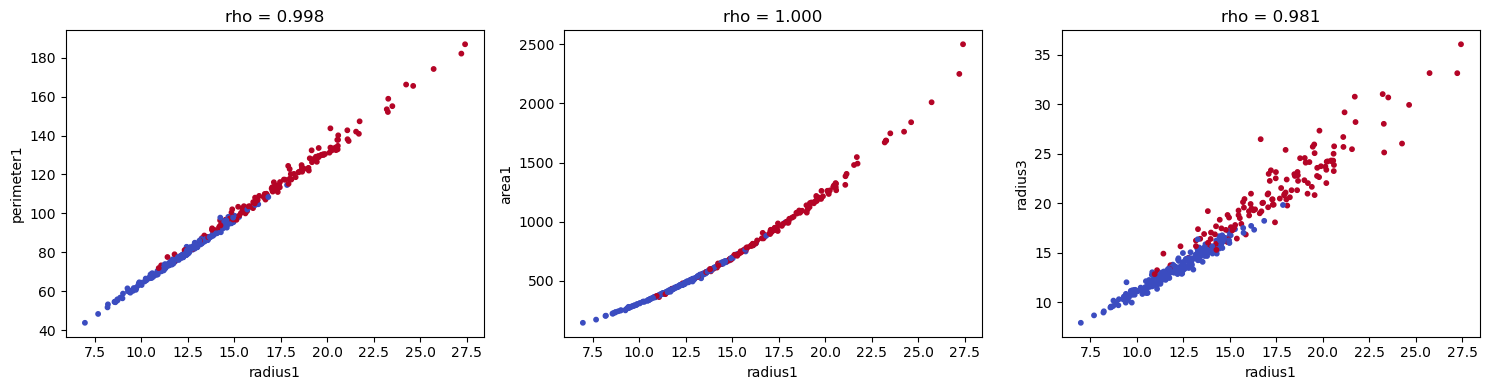

In [7]:
tamano = [f"{m}{s}" for s in "123" for m in ("radius", "perimeter", "area")]
display(corr_train.loc[tamano, tamano])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (vx, vy) in zip(ax, [("radius1", "perimeter1"), ("radius1", "area1"), ("radius1", "radius3")]):
    a.scatter(X_train[vx], X_train[vy], c=y_train, cmap="coolwarm", s=10)
    a.set(xlabel=vx, ylabel=vy, title=f"rho = {corr_train.loc[vx, vy]:.3f}")
plt.tight_layout(); plt.show()

### 4.2 Media vs. error estándar vs. peor valor, y textura

Para cada medida, ¿qué tan parecidos son sus tres resúmenes?

In [8]:
medidas = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
           "concavity", "concave_points", "symmetry", "fractal_dimension"]
tabla = pd.DataFrame({
    "media~peor": [corr_train.loc[f"{m}1", f"{m}3"] for m in medidas],
    "media~se": [corr_train.loc[f"{m}1", f"{m}2"] for m in medidas],
    "se~peor": [corr_train.loc[f"{m}2", f"{m}3"] for m in medidas],
}, index=medidas)
display(tabla)

UMBRAL_REDUNDANCIA = 0.90
pares = (corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1))
         .stack().rename("spearman").reset_index())
pares = pares[pares["spearman"].abs() >= UMBRAL_REDUNDANCIA].sort_values("spearman", key=abs, ascending=False)
print(f"Pares con |rho| >= {UMBRAL_REDUNDANCIA}: {len(pares)} de {30 * 29 // 2}")
display(pares.reset_index(drop=True))

,media~peor,media~se,se~peor
radius,0.981,0.556,0.600
texture,0.909,0.431,0.483
perimeter,0.982,0.588,0.632
area,0.983,0.739,0.769
smoothness,0.828,0.336,0.378
compactness,0.901,0.815,0.785
concavity,0.936,0.859,0.810
concave_points,0.938,0.770,0.701
symmetry,0.711,0.394,0.283
fractal_dimension,0.736,0.628,0.679


Pares con |rho| >= 0.9: 26 de 435


,level_0,level_1,spearman
0,radius1,area1,1.000
1,radius3,area3,0.999
2,radius1,perimeter1,0.998
3,perimeter1,area1,0.997
4,radius3,perimeter3,0.994
5,perimeter3,area3,0.992
6,perimeter1,area3,0.984
7,perimeter1,radius3,0.983
8,area1,area3,0.983
9,radius1,area3,0.983


Lectura:

- **Radio, perímetro y área** son prácticamente la misma variable (ρ ≈ 0,99–1,00 dentro de cada
  resumen), y además su **media** y su **peor valor** también están muy correlacionados (ρ ≈ 0,97).
  Hay ~9 columnas que codifican un solo concepto: el **tamaño** del núcleo.
- **Textura** forma su propio bloque (`texture1` ~ `texture3` muy correlacionadas) pero es casi
  independiente del tamaño: aporta información distinta.
- **Concavidad, compacidad y puntos cóncavos** forman otro bloque (forma del contorno).
- Los **errores estándar** (`*2`) están menos correlacionados con la media y el peor valor: miden
  variabilidad entre núcleos, que es otra cosa.

### 4.3 Relevancia individual: separación entre clases

,F_anova,p_valor,info_mutua
concave_points3,575.592,4.754e-75,0.436
perimeter3,539.160,4.729e-72,0.448
concave_points1,533.037,1.552e-71,0.456
radius3,517.155,3.518e-70,0.457
perimeter1,429.967,2.946e-62,0.415
radius1,402.343,1.475e-59,0.381
area3,386.711,5.515e-58,0.449
area1,353.575,1.552e-54,0.375
concavity1,325.497,1.764e-51,0.347
concavity3,230.803,4.021e-40,0.290


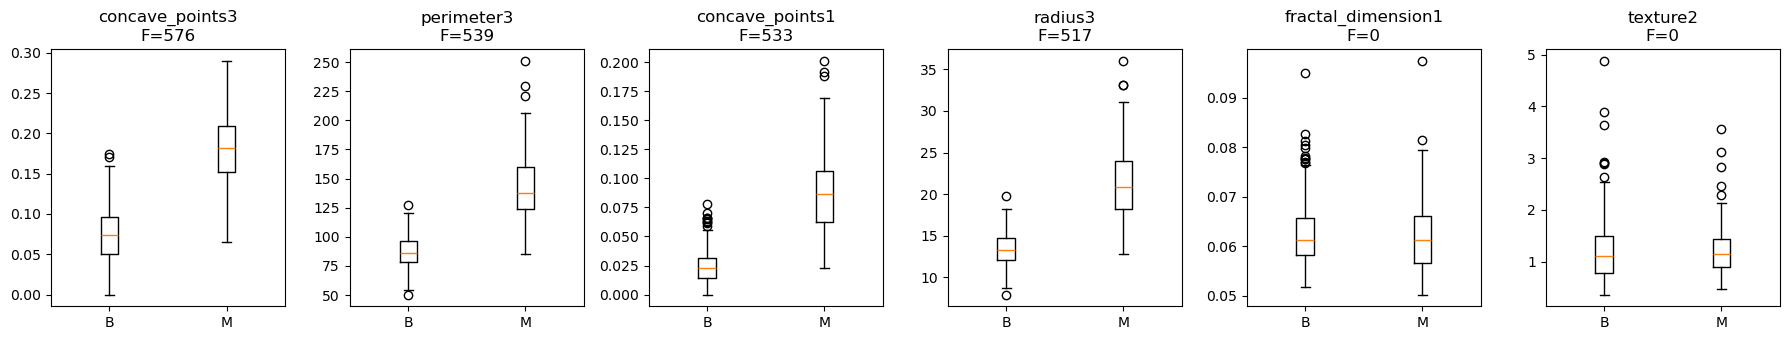

In [9]:
F, p_anova = f_classif(X_train, y_train)
relevancia = pd.DataFrame({
    "F_anova": F,
    "p_valor": p_anova,
    "info_mutua": mutual_info_classif(X_train, y_train, random_state=SEMILLA),
}, index=X.columns).sort_values("F_anova", ascending=False)
display(relevancia)

top = relevancia.index[:4].tolist() + relevancia.index[-2:].tolist()
fig, ax = plt.subplots(1, len(top), figsize=(18, 3.5))
for a, v in zip(ax, top):
    a.boxplot([X_train.loc[y_train == 0, v], X_train.loc[y_train == 1, v]], labels=["B", "M"])
    a.set_title(f"{v}\nF={relevancia.loc[v, 'F_anova']:.0f}")
plt.tight_layout(); plt.show()

Las variables de **tamaño "peor"** y de **puntos cóncavos** separan muy bien las clases; en el extremo
opuesto, varias de error estándar (p. ej. `smoothness2`, `fractal_dimension2`) prácticamente no
separan. Pero ojo: los primeros puestos del ranking son casi todos del mismo bloque redundante, así que
quedarse con "el top-k" a secas daría varias copias de la misma información.

## 5. Rankings y subconjuntos candidatos (actividad 3)

Se implementan cuatro técnicas de las sugeridas. Cada una es una función que **recibe solo datos de
entrenamiento** y devuelve una lista de columnas, para poder reaplicarla dentro de cada fold de CV:

| Candidato | Técnica |
|---|---|
| S1 | **ANOVA F** + control de redundancia (voraz: se agrega una variable si su \|ρ\| con las ya elegidas es < 0,90) |
| S2 | **Información mutua** + el mismo control de redundancia |
| S3 | **Regresión logística L1** (C elegido por CV dentro de train, con escalado y penalización ajustados dentro de cada fold): variables con coeficiente ≠ 0 |
| S4 | **RFE** con regresión logística (eliminación recursiva hasta *k* variables) |

In [10]:
def crear_rna(semilla=SEMILLA):
    # Arquitectura, preprocesamiento y semilla del código inicial; única definición de modelo.
    return Pipeline([
        ("scaler", StandardScaler()),
        ("mlp", MLPClassifier(
            hidden_layer_sizes=(32, 16),
            activation="relu",
            max_iter=1000,
            random_state=semilla,
        )),
    ])


def sin_redundancia(puntajes, k, X_ref, umbral=UMBRAL_REDUNDANCIA):
    corr = X_ref.corr(method="spearman").abs()
    elegidas = []
    for v in puntajes.sort_values(ascending=False).index:
        if all(corr.loc[v, o] < umbral for o in elegidas):
            elegidas.append(v)
        if len(elegidas) == k:
            break
    return elegidas


def sel_anova(Xa, ya, k):
    return sin_redundancia(pd.Series(f_classif(Xa, ya)[0], index=Xa.columns), k, Xa)


def sel_info_mutua(Xa, ya, k):
    return sin_redundancia(pd.Series(mutual_info_classif(Xa, ya, random_state=SEMILLA), index=Xa.columns), k, Xa)


def sel_l1(Xa, ya, k=None):
    # El escalador va dentro del Pipeline que evalúa GridSearchCV: en cada fold interno
    # se ajustan escala y penalización solo con la parte de entrenamiento de ese fold.
    busqueda = GridSearchCV(
        Pipeline([("scaler", StandardScaler()),
                  ("lr", LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000, random_state=SEMILLA))]),
        {"lr__C": np.logspace(-4, 4, 20)},
        cv=StratifiedKFold(n_splits=5),
        scoring="f1",
    ).fit(Xa, ya)
    coef = pd.Series(busqueda.best_estimator_[-1].coef_[0], index=Xa.columns)
    return list(coef[coef != 0].abs().sort_values(ascending=False).index)


def sel_rfe(Xa, ya, k):
    Xs = StandardScaler().fit_transform(Xa)
    rfe = RFE(LogisticRegression(max_iter=5000), n_features_to_select=k).fit(Xs, ya)
    return list(Xa.columns[rfe.support_])


SELECTORES = {"ANOVA": sel_anova, "Info mutua": sel_info_mutua, "L1": sel_l1, "RFE": sel_rfe}


def metricas(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred),
            "FN (malignos no detectados)": fn, "FP": fp}

### 5.1 Elección de *k* con validación cruzada **dentro de train**

El conjunto de validación tiene solo 114 casos (43 malignos): un solo error mueve el recall ~2 puntos.
Para elegir el tamaño *k* de forma más estable se usa **validación cruzada estratificada repetida
(5 folds × 3) sobre `X_train`**, y en cada fold la selección se recalcula usando solo la parte de
entrenamiento del fold (si se seleccionara con todo train y después se hiciera CV, habría fuga).

Criterio: mayor **F1** medio; con diferencias menores a 0,005 se prefiere el *k* más chico.
Además se guardan las variables elegidas en cada fold para medir **estabilidad**.

In [11]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
folds = list(cv.split(X_train, y_train))


def cv_seleccion(selector, k):
    filas, elegidas = [], []
    for tr, te in folds:
        Xa, ya = X_train.iloc[tr], y_train.iloc[tr]
        cols = list(X.columns) if selector is None else selector(Xa, ya, k)
        pred = crear_rna().fit(Xa[cols], ya).predict(X_train.iloc[te][cols])
        filas.append(metricas(y_train.iloc[te], pred))
        elegidas.append(cols)
    return pd.DataFrame(filas).mean(), elegidas


registro = []
elegidas_por_config = {}
res, el = cv_seleccion(None, None)
registro.append({"método": "todas", "k": 30, **res}); elegidas_por_config[("todas", 30)] = el
for nombre in ["ANOVA", "Info mutua", "RFE"]:
    for k in [3, 5, 8, 10, 15]:
        res, el = cv_seleccion(SELECTORES[nombre], k)
        registro.append({"método": nombre, "k": k, **res}); elegidas_por_config[(nombre, k)] = el
res, el = cv_seleccion(sel_l1, None)
registro.append({"método": "L1", "k": round(np.mean([len(e) for e in el]), 1), **res}); elegidas_por_config[("L1", None)] = el
cv_res = pd.DataFrame(registro)
display(cv_res)

,método,k,accuracy,precision,recall,F1,FN (malignos no detectados),FP
0,todas,30.0,0.967,0.971,0.940,0.954,1.533,0.733
1,ANOVA,3.0,0.928,0.909,0.901,0.902,2.533,2.400
2,ANOVA,5.0,0.938,0.930,0.906,0.917,2.400,1.800
3,ANOVA,8.0,0.953,0.949,0.927,0.936,1.867,1.333
4,ANOVA,10.0,0.962,0.967,0.932,0.948,1.733,0.867
5,ANOVA,15.0,0.963,0.964,0.937,0.950,1.600,0.933
6,Info mutua,3.0,0.926,0.912,0.890,0.899,2.800,2.267
7,Info mutua,5.0,0.931,0.925,0.887,0.905,2.867,1.867
8,Info mutua,8.0,0.962,0.954,0.945,0.949,1.400,1.200
9,Info mutua,10.0,0.965,0.966,0.940,0.952,1.533,0.867


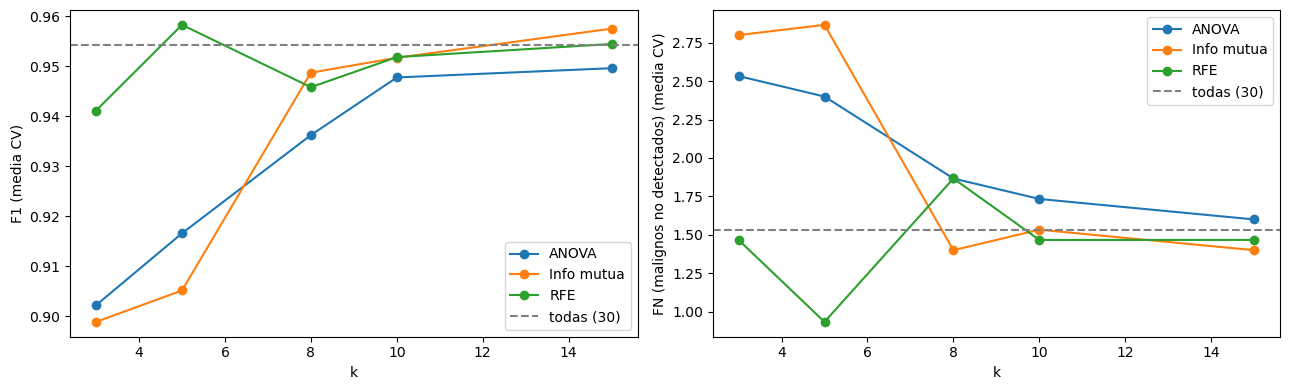

k elegido: {'ANOVA': 10, 'Info mutua': 15, 'RFE': 5}


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for nombre in ["ANOVA", "Info mutua", "RFE"]:
    g = cv_res[cv_res["método"] == nombre]
    ax[0].plot(g["k"], g["F1"], marker="o", label=nombre)
    ax[1].plot(g["k"], g["FN (malignos no detectados)"], marker="o", label=nombre)
for a, col in zip(ax, ["F1", "FN (malignos no detectados)"]):
    a.axhline(cv_res.loc[cv_res["método"] == "todas", col].item(), color="gray", ls="--", label="todas (30)")
    a.set(xlabel="k", ylabel=col + " (media CV)"); a.legend()
plt.tight_layout(); plt.show()


def elegir_k(nombre):
    g = cv_res[cv_res["método"] == nombre].sort_values("k")
    return int(g[g["F1"] >= g["F1"].max() - 0.005]["k"].iloc[0])


k_elegido = {n: elegir_k(n) for n in ["ANOVA", "Info mutua", "RFE"]}
print("k elegido:", k_elegido)

### 5.2 Estabilidad de la selección entre folds

Para cada método (con su *k* elegido) se mide en cuántos de los 15 folds aparece cada variable y el
**índice de Jaccard** medio entre los subconjuntos de pares de folds (1 = siempre el mismo subconjunto).

In [13]:
def jaccard_medio(listas):
    s = [set(l) for l in listas]
    return np.mean([len(a & b) / len(a | b) for i, a in enumerate(s) for b in s[i + 1:]])


claves = {"S1 ANOVA": ("ANOVA", k_elegido["ANOVA"]), "S2 Info mutua": ("Info mutua", k_elegido["Info mutua"]),
          "S3 L1": ("L1", None), "S4 RFE": ("RFE", k_elegido["RFE"])}
frecuencias = {}
for etiqueta, clave in claves.items():
    listas = elegidas_por_config[clave]
    frecuencias[etiqueta] = pd.Series([v for l in listas for v in l]).value_counts() / len(listas)
    print(f"{etiqueta:14s} k={np.mean([len(l) for l in listas]):4.1f}  Jaccard medio entre folds = {jaccard_medio(listas):.2f}")
frecuencias = pd.DataFrame(frecuencias).fillna(0).sort_values("S1 ANOVA", ascending=False)
display(frecuencias.style.format("{:.0%}").background_gradient(cmap="Greens", vmin=0, vmax=1))

S1 ANOVA       k=10.0  Jaccard medio entre folds = 0.69
S2 Info mutua  k=15.0  Jaccard medio entre folds = 0.78
S3 L1          k= 9.3  Jaccard medio entre folds = 0.60
S4 RFE         k= 5.0  Jaccard medio entre folds = 0.74


,S1 ANOVA,S2 Info mutua,S3 L1,S4 RFE
texture3,100%,100%,100%,100%
compactness1,100%,100%,0%,0%
symmetry3,100%,100%,93%,0%
concave_points2,100%,100%,13%,0%
perimeter3,100%,67%,13%,60%
smoothness3,93%,100%,100%,0%
concave_points3,93%,7%,27%,47%
concavity3,67%,100%,60%,0%
symmetry1,60%,100%,7%,0%
radius2,60%,0%,67%,0%


### 5.3 Candidatos definitivos (cada técnica aplicada a todo `X_train`)

In [14]:
candidatos = {
    "todas (30)": list(X.columns),
    f"S1 ANOVA+redund. (k={k_elegido['ANOVA']})": sel_anova(X_train, y_train, k_elegido["ANOVA"]),
    f"S2 Info mutua+redund. (k={k_elegido['Info mutua']})": sel_info_mutua(X_train, y_train, k_elegido["Info mutua"]),
    "S3 L1": sel_l1(X_train, y_train),
    f"S4 RFE (k={k_elegido['RFE']})": sel_rfe(X_train, y_train, k_elegido["RFE"]),
}
for nombre, cols in candidatos.items():
    print(f"{nombre:28s} ({len(cols):2d}) -> {cols}")

todas (30)                   (30) -> ['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']
S1 ANOVA+redund. (k=10)      (10) -> ['concave_points3', 'perimeter3', 'concavity3', 'compactness1', 'radius2', 'texture3', 'symmetry3', 'concave_points2', 'smoothness3', 'symmetry1']
S2 Info mutua+redund. (k=15) (15) -> ['radius3', 'concave_points1', 'area2', 'concavity3', 'compactness1', 'texture3', 'concave_points2', 'symmetry1', 'concavity2', 'symmetry3', 'smoothness3', 'fractal_dimension3', 'smoothness1', 'fractal_dimension2', 'compactness2']
S3 L1                        (11) -> ['area3', 'concave_points1', 'texture3

## 6. Comparación en validación con la misma arquitectura (actividades 4 y 6)

Misma `crear_rna()`, mismas particiones, misma semilla. Se reportan todas las métricas pedidas y la
matriz de confusión; la columna **FN** cuenta los malignos que el modelo clasificó como benignos.

,n_vars,accuracy,precision,recall,F1,FN (malignos no detectados),FP
todas (30),30,0.965,0.933,0.977,0.955,1,3
S1 ANOVA+redund. (k=10),10,0.956,0.913,0.977,0.944,1,4
S2 Info mutua+redund. (k=15),15,0.956,0.913,0.977,0.944,1,4
S3 L1,11,0.974,0.955,0.977,0.966,1,2
S4 RFE (k=5),5,0.956,0.932,0.953,0.943,2,3


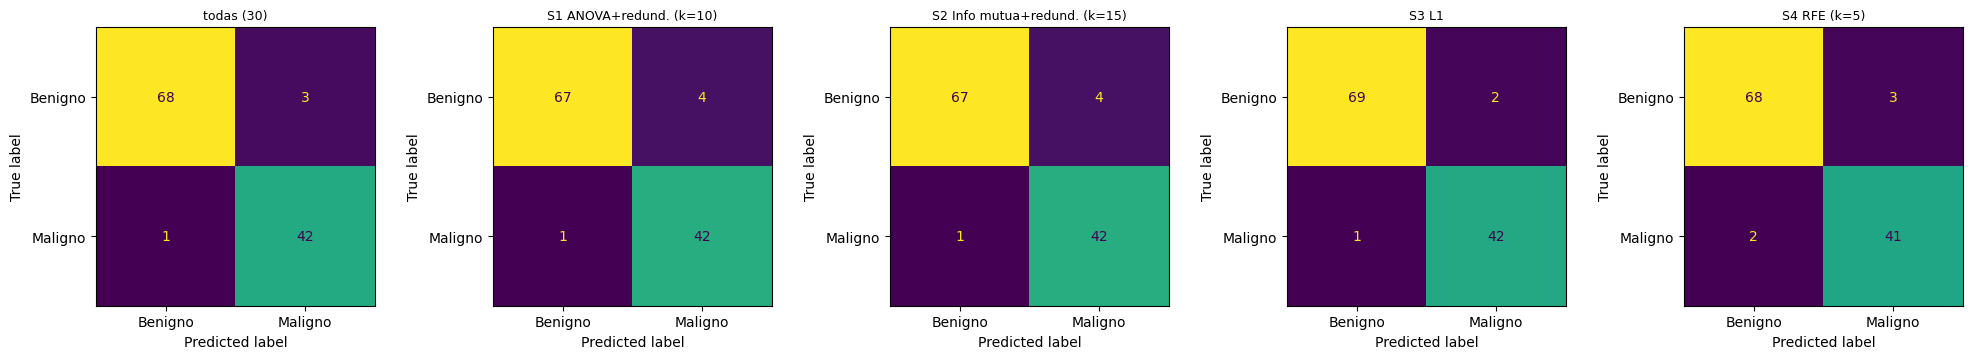

In [15]:
resultados_val, matrices = {}, {}
for nombre, cols in candidatos.items():
    pred = crear_rna().fit(X_train[cols], y_train).predict(X_val[cols])
    resultados_val[nombre] = {"n_vars": len(cols), **metricas(y_val, pred)}
    matrices[nombre] = confusion_matrix(y_val, pred)
resultados_val = pd.DataFrame(resultados_val).T
resultados_val[["n_vars", "FN (malignos no detectados)", "FP"]] = resultados_val[["n_vars", "FN (malignos no detectados)", "FP"]].astype(int)
display(resultados_val)

fig, ax = plt.subplots(1, len(matrices), figsize=(4 * len(matrices), 3.6))
for a, (nombre, m) in zip(ax, matrices.items()):
    ConfusionMatrixDisplay(m, display_labels=["Benigno", "Maligno"]).plot(ax=a, colorbar=False)
    a.set_title(nombre, fontsize=9)
plt.tight_layout(); plt.show()

### 6.1 Control de sensibilidad a la semilla

La comparación principal usa siempre la semilla 42. Como control adicional, se repite con otras
semillas para ver si las diferencias son sistemáticas o efecto de la inicialización.

In [16]:
filas = []
for semilla in [0, 1, 2, 3, 4, 42]:
    for nombre, cols in candidatos.items():
        pred = crear_rna(semilla).fit(X_train[cols], y_train).predict(X_val[cols])
        filas.append({"semilla": semilla, "conjunto": nombre, **metricas(y_val, pred)})
por_semilla = pd.DataFrame(filas)
display(por_semilla.groupby("conjunto")[["accuracy", "recall", "F1", "FN (malignos no detectados)"]].agg(["mean", "std"]))

accuracy        recall            F1         \
                                 mean    std   mean    std   mean    std   
conjunto                                                                   
S1 ANOVA+redund. (k=10)         0.952  0.012  0.977  0.000  0.939  0.015   
S2 Info mutua+redund. (k=15)    0.950  0.007  0.965  0.013  0.936  0.009   
S3 L1                           0.972  0.004  0.977  0.000  0.964  0.004   
S4 RFE (k=5)                    0.955  0.007  0.953  0.000  0.941  0.008   
todas (30)                      0.972  0.009  0.977  0.000  0.964  0.011   

                             FN (malignos no detectados)         
                                                    mean    std  
conjunto                                                         
S1 ANOVA+redund. (k=10)                              1.0  0.000  
S2 Info mutua+redund. (k=15)                         1.5  0.548  
S3 L1                                                1.0  0.000  
S4 RFE (k=5)                                         2.0  0.000  
todas (30)                                           1.0  0.000

## 7. Selección final y justificación (actividad 7)

In [17]:
PREFIJO_FINAL = "S3"
NOMBRE_FINAL = next(n for n in candidatos if n.startswith(PREFIJO_FINAL))
seleccion_final = candidatos[NOMBRE_FINAL]
print(f"Selección final: {NOMBRE_FINAL} -> {len(seleccion_final)} variables")
display(pd.concat([relevancia.loc[seleccion_final, ["F_anova", "info_mutua"]],
                   frecuencias.loc[seleccion_final]], axis=1))

Selección final: S3 L1 -> 11 variables


,F_anova,info_mutua,S1 ANOVA,S2 Info mutua,S3 L1,S4 RFE
area3,386.711,0.449,0.000,0.200,0.867,0.8
concave_points1,533.037,0.456,0.067,0.933,1.000,1.0
texture3,104.504,0.158,1.000,1.000,1.000,1.0
radius3,517.155,0.457,0.000,0.133,0.800,1.0
radius2,171.177,0.225,0.600,0.000,0.667,0.0
symmetry3,81.519,0.093,1.000,1.000,0.933,0.0
smoothness3,65.529,0.090,0.933,1.000,1.000,0.0
fractal_dimension2,2.989,0.034,0.000,0.667,0.733,0.0
concavity3,230.803,0.290,0.667,1.000,0.600,0.0
smoothness2,0.765,0.019,0.000,0.467,0.267,0.0


**Selección final: S3 — regresión logística L1, 11 variables:**
`area3`, `concave_points1`, `texture3`, `radius3`, `radius2`, `symmetry3`, `smoothness3`,
`fractal_dimension2`, `concavity3`, `smoothness2`, `fractal_dimension1`.

La decisión se tomó **solo con CV dentro de train y con validación**, antes de mirar la prueba,
considerando los tres criterios que pide la consigna:

| Criterio | Evidencia | Lectura |
|---|---|---|
| **Desempeño** | Validación: F1 0,966, accuracy 0,974, **1 FN** y 2 FP, contra F1 0,955 / 1 FN / 3 FP de las 30 variables. En CV (5×3 sobre train): F1 0,960 y 1,20 FN por fold, contra 0,954 / 1,53 de las 30. | Es el único candidato que **no pierde nada** frente a las 30 en ninguna de las dos mediciones (en CV incluso las supera levemente). S1 y S2 pierden ~1 punto de F1 en validación; S4 (RFE, 5 variables) queda cerca en CV (F1 0,958), pero en validación deja escapar 2 malignos. |
| **Estabilidad** | Con 6 semillas distintas, S3 tiene F1 0,964 ± 0,004 y FN = 1 en todas; las 30 variables, 0,964 ± 0,011. El Jaccard entre folds es 0,60, el más bajo. | El **resultado** es muy estable (incluso menos variable que con 30). Las **columnas exactas** rotan más entre folds, pero lo que rota es qué representante del bloque tamaño entra (`area3` en el 87 % de los folds, `radius3` en el 80 %) o de concavidad; `concave_points1`, `texture3` y `smoothness3` salen en el **100 %** de los folds y `symmetry3`, en el 93 %. |
| **Cantidad de variables** | 11 de 30 (−63 %). | Menos entradas → menos pesos en la primera capa (11×32 en vez de 30×32) y menos mediciones a calcular. |

**Sobre la redundancia.** La selección cubre los grupos de información que se vieron en la sección 4:
**tamaño** (`area3`, `radius3`, `radius2`), **forma del contorno** (`concave_points1`, `concavity3`),
**textura** (`texture3`) y **regularidad** (`symmetry3`, `smoothness3`, `fractal_dimension*`,
`smoothness2`). Descarta 10 de las 12 columnas de tamaño y casi todos los errores estándar.
Mantiene el par `area3`/`radius3` (ρ = 0,999): con L1 eso no es "duplicar" sino combinarlas —
como área ≈ πr², su diferencia aporta un poco de información sobre la forma—, y RFE eligió
lo mismo de forma independiente. También incluye `fractal_dimension1` y `smoothness2`, que por
separado casi no separan clases (F < 1): L1 las usa **en combinación** con el resto, algo que un
filtro univariado como ANOVA no puede captar. Las dos tienen frecuencias bajas entre folds (13 % y 27 %),
así que son las candidatas naturales a quitar si se quisiera un conjunto todavía más chico.

## 8. Evaluación final en prueba (una sola vez)

Configuración congelada: `crear_rna()`, semilla 42, entrenada con `X_train`. Única celda que usa `X_test`.


=== todas (30) — prueba ===
              precision    recall  f1-score   support

     Benigno      0.959     0.972     0.966        72
     Maligno      0.951     0.929     0.940        42

    accuracy                          0.956       114
   macro avg      0.955     0.950     0.953       114
weighted avg      0.956     0.956     0.956       114


=== selección final (11) — prueba ===
              precision    recall  f1-score   support

     Benigno      0.972     0.958     0.965        72
     Maligno      0.930     0.952     0.941        42

    accuracy                          0.956       114
   macro avg      0.951     0.955     0.953       114
weighted avg      0.957     0.956     0.956       114



accuracy  precision  recall     F1  \
conjunto             partición                                        
todas (30)           validación     0.965      0.933   0.977  0.955   
                     prueba         0.956      0.951   0.929  0.940   
selección final (11) validación     0.974      0.955   0.977  0.966   
                     prueba         0.956      0.930   0.952  0.941   

                                 FN (malignos no detectados)  FP  
conjunto             partición                                    
todas (30)           validación                            1   3  
                     prueba                                3   2  
selección final (11) validación                            1   2  
                     prueba                                2   3

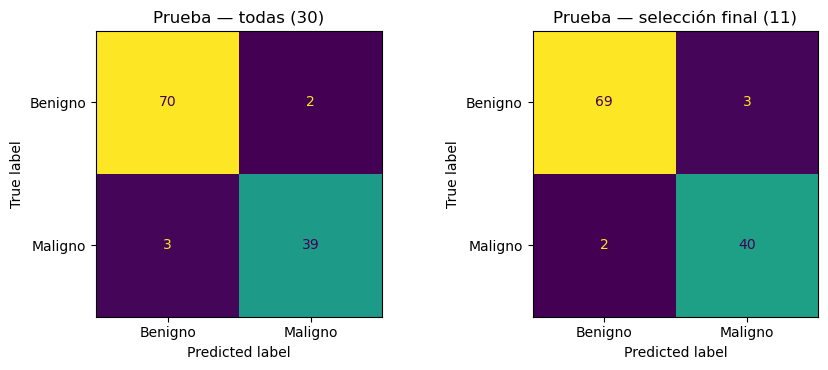

In [18]:
filas, matrices_test = [], {}
for nombre, cols in [("todas (30)", list(X.columns)), (f"selección final ({len(seleccion_final)})", seleccion_final)]:
    modelo = crear_rna().fit(X_train[cols], y_train)
    for particion, Xe, ye in [("validación", X_val, y_val), ("prueba", X_test, y_test)]:
        pred = modelo.predict(Xe[cols])
        filas.append({"conjunto": nombre, "partición": particion, **metricas(ye, pred)})
        if particion == "prueba":
            matrices_test[nombre] = confusion_matrix(ye, pred)
            print(f"\n=== {nombre} — prueba ===")
            print(classification_report(ye, pred, target_names=["Benigno", "Maligno"], digits=3))
display(pd.DataFrame(filas).set_index(["conjunto", "partición"]))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (nombre, m) in zip(ax, matrices_test.items()):
    ConfusionMatrixDisplay(m, display_labels=["Benigno", "Maligno"]).plot(ax=a, colorbar=False)
    a.set_title(f"Prueba — {nombre}")
plt.tight_layout(); plt.show()

## 9. Conclusión

Con la misma RNA, particiones y semilla, las 11 variables elegidas por L1 rinden igual que las 30 en prueba (accuracy 0,956 en ambos casos; F1 0,941 contra 0,940) y detectan un maligno más (2 FN contra 3), a cambio de un falso positivo extra. Como la diferencia es de un solo caso, no se concluye que el subconjunto sea mejor, sino que con un tercio de las variables, y sin la redundancia de radio, perímetro y área, se obtiene el mismo desempeño de forma estable. Es un ejercicio educativo, no una herramienta clínica.